In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df_recife = pd.read_csv('../dados/df_recife.csv')
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="white")

# Copiar os dados
df_cluster = df_recife.copy()

col_umidade = "UMIDADE RELATIVA DO AR, HORARIA (%)"
col_chuva = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"

# Converter datetime e variáveis numéricas
df_cluster["datetime"] = pd.to_datetime(
    df_cluster["datetime"], errors="coerce"
)

for coluna in [col_umidade, col_chuva]:
    df_cluster[coluna] = pd.to_numeric(
        df_cluster[coluna], errors="coerce"
    ).replace(-9999, np.nan)

# Ordenar cronologicamente
df_cluster = (
    df_cluster.dropna(subset=["datetime"])
    .sort_values("datetime")
    .reset_index(drop=True)
)

# Calcular variação de umidade somente entre horas consecutivas
intervalo = df_cluster["datetime"].diff()
variacao = df_cluster[col_umidade].diff()

df_cluster["variacao_umidade"] = variacao.where(
    intervalo == pd.Timedelta(hours=1)
)

# Selecionar as variáveis de agrupamento
variaveis_cluster = [
    col_umidade,
    "variacao_umidade"
]

# Remover apenas linhas sem as variáveis necessárias
df_modelo = df_cluster.dropna(
    subset=variaveis_cluster
).copy()

print("Registros originais:", len(df_recife))
print("Registros utilizados no clustering:", len(df_modelo))
print("Registros removidos:", len(df_recife) - len(df_modelo))

display(df_modelo[variaveis_cluster].describe().round(2))

Registros originais: 17544
Registros utilizados no clustering: 17517
Registros removidos: 27


,"UMIDADE RELATIVA DO AR, HORARIA (%)",variacao_umidade
count,17517.00,17517.00
mean,76.93,-0.00
std,12.50,4.69
min,40.00,-29.00
25%,67.00,-1.00
50%,77.00,0.00
75%,89.00,2.00
max,94.00,21.00


In [71]:
# Padronizar os dados
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df_modelo[variaveis_cluster]
)

# Executar DBSCAN
modelo_dbscan = DBSCAN(
    eps=0.70,
    min_samples=20
)

df_modelo["cluster"] = modelo_dbscan.fit_predict(X_scaled)

# Incorporar os rótulos ao DataFrame principal
df_cluster["cluster"] = pd.Series(
    index=df_cluster.index,
    dtype="Int64"
)

df_cluster.loc[df_modelo.index, "cluster"] = (
    df_modelo["cluster"].astype("Int64")
)

# Resumo dos agrupamentos
rotulos = df_modelo["cluster"]
n_clusters = len(set(rotulos) - {-1})
n_ruido = (rotulos == -1).sum()

print("Quantidade de clusters encontrados:", n_clusters)
print("Registros classificados como ruído:", n_ruido)
print(f"Percentual de ruído: {n_ruido / len(df_modelo) * 100:.2f}%")

display(
    df_modelo["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Quantidade de registros")
)

Quantidade de clusters encontrados: 1
Registros classificados como ruído: 0
Percentual de ruído: 0.00%


,Quantidade de registros
Cluster,
0,17517


In [72]:

resultados = []

# Testar diferentes combinações
for eps in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60, 0.70]:
    for min_samples in [5, 10, 15, 20]:
        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = modelo.fit_predict(X_scaled)

        n_clusters = len(set(labels) - {-1})
        percentual_ruido = (labels == -1).mean() * 100

        tamanhos = pd.Series(labels)
        tamanhos = tamanhos[tamanhos != -1].value_counts()

        maior_cluster_pct = (
            tamanhos.max() / len(labels) * 100
            if len(tamanhos) > 0 else 0
        )

        resultados.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "ruido_pct": round(percentual_ruido, 2),
            "maior_cluster_pct": round(maior_cluster_pct, 2)
        })

resultado_parametros = pd.DataFrame(resultados)

display(
    resultado_parametros.sort_values(
        ["n_clusters", "ruido_pct"],
        ascending=[False, True]
    ).reset_index(drop=True)
)

,eps,min_samples,n_clusters,ruido_pct,maior_cluster_pct
0,0.15,5,55,1.11,20.35
1,0.15,10,47,2.84,20.31
2,0.20,5,44,0.58,20.35
3,0.15,20,43,8.51,20.24
4,0.15,15,40,5.81,20.30
5,0.20,10,36,1.46,20.34
6,0.20,15,33,2.35,20.33
7,0.20,20,32,3.82,20.31
8,0.25,10,2,0.25,99.73
9,0.60,5,1,0.00,100.00


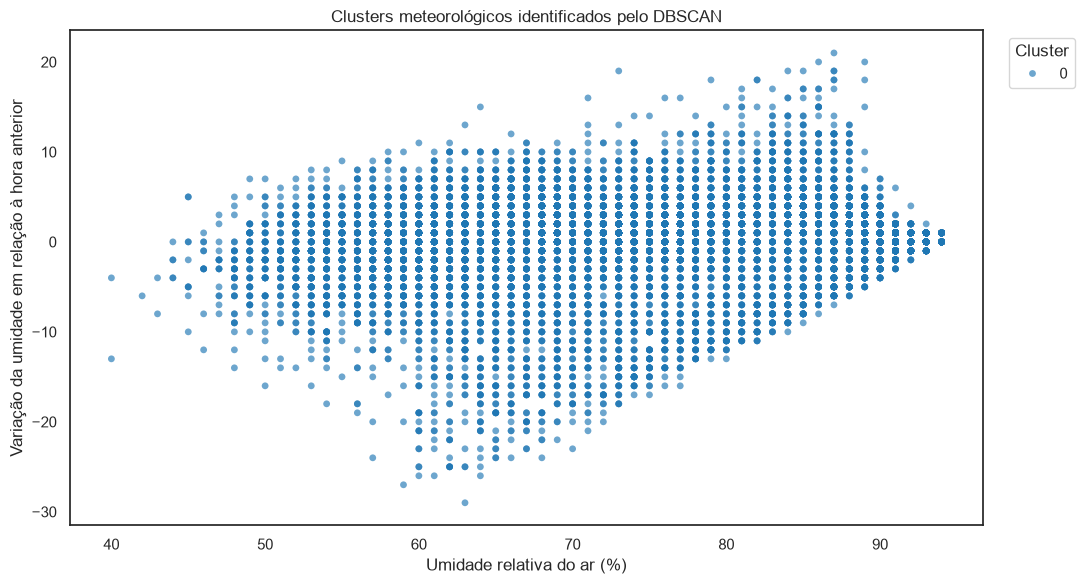

In [73]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_modelo,
    x=col_umidade,
    y="variacao_umidade",
    hue="cluster",
    palette="tab10",
    alpha=0.65,
    s=24,
    linewidth=0
)

plt.title("Clusters meteorológicos identificados pelo DBSCAN")
plt.xlabel("Umidade relativa do ar (%)")
plt.ylabel("Variação da umidade em relação à hora anterior")
plt.legend(
    title="Cluster",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [74]:
df_modelo["chuva_forte"] = (
    df_modelo[col_chuva] >= 25
)

resumo_clusters = (
    df_modelo.groupby("cluster")
    .agg(
        registros=(col_umidade, "size"),
        umidade_media=(col_umidade, "mean"),
        variacao_media=("variacao_umidade", "mean"),
        precipitacao_media=(col_chuva, "mean"),
        registros_com_precipitacao=(col_chuva, "count"),
        eventos_chuva_forte=("chuva_forte", "sum")
    )
    .round(2)
)

display(resumo_clusters)

,registros,umidade_media,variacao_media,precipitacao_media,registros_com_precipitacao,eventos_chuva_forte
cluster,,,,,,
0,17517,76.93,-0.0,0.04,15505,1


O método do DBSCAN não foi efetivo para clusterizar a base pela umidade do ar, nos diferentes testes o programa tefe dificuldade em separar uma diferença notável para os clusters